# Backpropagation: Passing the Blame Backward

*How a network works out, for every single weight, which way is downhill.*

At the end of [Lesson 4](04_MultiLayerPerceptrons.ipynb) we had a 2-2-1
network that solved **XOR** perfectly, but only because we hand-copied
weights for OR, NAND and AND from [Lesson 2](02_Perceptrons.ipynb). We knew
the answer before we started. Real problems don't come with the answer
attached: the network has to **find its own weights from data**.

We already know the tool for finding weights: **gradient descent**, from
[Lesson 1](01_GradientDescent.ipynb). It needs just one thing: the slope of
the loss with respect to *every* weight in the network. For a single neuron,
[Lesson 3](03_ActivationFunctions.ipynb) handed us that slope as a ready-made
formula. For a network with a hidden layer, a hidden weight doesn't touch the
loss directly. Its effect passes *through* other neurons before it reaches
the prediction. This lesson is about how to follow that chain of effects.
The method is called **backpropagation**.

By the end you will be able to:

1. State the **chain rule** from calculus, both informally ("rates multiply
   along a chain") and formally, and check it numerically.
2. Explain why estimating slopes by **nudging** each weight works, but is far
   too slow for real networks.
3. Carry out a **forward pass and a backward pass by hand** on a tiny network,
   and check every slope against nudging.
4. Write the backward pass for a whole layer in **matrix form**, next to
   Lesson 4's `forward_pass`.
5. **Train a network to solve XOR from scratch** and look at the hidden-layer
   representation it invents on its own.
6. Recognize a few common ways training goes wrong.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Recap: the loose end

Here are the same XOR data and the same forward pass as Lesson 4. We make
one change: every neuron now uses **sigmoid** instead of `step`. Lesson 3
explained why. Gradient descent needs a slope to follow, and the step
function doesn't have one.

In [2]:
# The same 4 points and XOR labels used throughout Lessons 2-4.
inputs = np.array(
    [
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1],
    ]
)
xor_labels = np.array([0, 1, 1, 0])

# The network outputs one column per output neuron, so keep the targets as a
# column too: shape (4, 1) instead of (4,).
Y = xor_labels.reshape(-1, 1)


def sigmoid(z):
    "Smoothly squashes any real number into the range (0, 1)."
    z = np.clip(z, -500, 500)  # avoid overflow warnings for very large |z|
    return 1 / (1 + np.exp(-z))


def sigmoid_grad(z):
    "The slope of the sigmoid function at z (from Lesson 3)."
    s = sigmoid(z)
    return s * (1 - s)


def forward_pass(X, W1, b1, W2, b2, activation=sigmoid):
    "Run a batch of inputs through a 2-layer network: (hidden output, final output)."
    Z1 = X @ W1 + b1
    A1 = activation(Z1)
    Z2 = A1 @ W2 + b2
    A2 = activation(Z2)
    return A1, A2


def mse(prediction, target):
    "Mean squared error, the same loss as Lessons 1 and 3."
    return np.mean((prediction - target) ** 2)

A network that hasn't been trained yet starts out with **random** weights. Let's
build one and see how it does:

In [3]:
rng = np.random.default_rng(0)
W1 = rng.normal(0, 1, size=(2, 2))  # 2 inputs  -> 2 hidden neurons
b1 = np.zeros(2)
W2 = rng.normal(0, 1, size=(2, 1))  # 2 hidden -> 1 output neuron
b2 = np.zeros(1)

_, prediction = forward_pass(inputs, W1, b1, W2, b2)

print(f"{'x1':>3} {'x2':>3} {'prediction':>11} {'target':>7}")
for x, pred, target in zip(inputs, prediction.flatten(), xor_labels):
    print(f"{x[0]:>3} {x[1]:>3} {pred:>11.3f} {target:>7}")
print(f"\nLoss (MSE): {mse(prediction, Y):.4f}")

 x1  x2  prediction  target
  0   0       0.478       0
  0   1       0.460       1
  1   0       0.471       1
  1   1       0.453       0

Loss (MSE): 0.2514


All four predictions come out close to each other, somewhere near the
middle. That's roughly what a random network does: it hasn't learned
anything, so it more or less shrugs. Our job is to turn these 9 random
numbers (4 weights in `W1`, 2 biases in `b1`, 2 weights in `W2`, 1 bias in
`b2`) into ones that solve XOR. Lesson 1's gradient descent loop will do
that, as long as we can answer one question for each of the 9 numbers:

> *If I increase this number a tiny bit, does the loss go up or down, and by how much?*

That's the slope of the loss with respect to that number. Everything else in
this lesson is about computing it.

## 2. Blame assignment, intuitively

Think of the network as a **relay race**. The input is the baton. The hidden
neurons each run a leg, the output neuron runs the last leg, and the loss is
the finishing time. The team lost. Whose fault was it, and by how much?

Only the last runner crosses the finish line, so we start there. The coach
can see directly how the final leg affected the result. To judge the
*second-to-last* runner, the coach asks two questions and multiplies the
answers:

1. How much did the last leg affect the finishing time?
2. How much did the second-to-last leg affect the last leg (for example, a
   clumsy handoff)?

The coach then keeps walking **backward** down the track, one handoff at a
time, reusing the answer from the leg just after. No one has to rerun the
race.

A neural network works the same way:

- The **output neuron** affects the loss directly, so its blame is easy to
  measure.
- A **hidden neuron** only affects the loss *through* the output neuron. Its
  blame is (the output neuron's blame) × (how strongly the hidden neuron
  pushes on the output neuron).
- A **weight feeding into a hidden neuron** only affects the loss through
  that hidden neuron, so its blame is the hidden neuron's blame times one
  more factor.

Blame flows from the loss **backward** toward the inputs, and at each
handoff we **multiply**. The mathematical fact that makes this correct is
called the **chain rule**. We'll look at it twice: first by feel, then as a
precise statement.

## 3. The chain rule, intuitively: rates multiply

### Gears

Picture three gears meshed in a row: A drives B, and B drives C.

- Every time **A** turns once, **B** turns **2** times.
- Every time **B** turns once, **C** turns **3** times.

How many times does C turn when A turns once? You don't need to watch the
gears to know: $2 \times 3 = 6$. The rate from A to C is the rate from A to
B **times** the rate from B to C.

The same idea shows up with currency exchange. Say 1 US dollar buys 150
Japanese yen, and 1 yen buys 7 Korean won. Then 1 dollar buys
$150 \times 7 = 1050$ won, without ever converting to yen and back.

### Slopes are rates

In Lesson 1 a slope meant "how steep the hill is." It's also a **rate**: if
the slope of $y$ with respect to $x$ is 2, then nudging $x$ by a tiny amount
changes $y$ by about **2 times** that amount. So when one quantity feeds into
another, which feeds into a third, the overall slope is the product of the
individual slopes, just like the gears.

Let's test this with two plain functions, feeding one into the other:

- inner function: $u = g(x) = 3x + 1$ (a straight line with slope 3 everywhere)
- outer function: $y = f(u) = u^2$ (Lesson 1's practice hill, slope $2u$)

We'll measure each slope separately using the nudging trick from Lesson 3,
then multiply the two together.

In [4]:
def numerical_slope(f, x, h=1e-5):
    "Estimate the slope of f at x from a tiny step forward and backward (Lesson 3)."
    return (f(x + h) - f(x - h)) / (2 * h)


def g(x):
    "Inner function: a straight line."
    return 3 * x + 1


def f(u):
    "Outer function: Lesson 1's practice hill."
    return u**2


def f_of_g(x):
    "The two chained together: x -> u -> y."
    return f(g(x))


x0 = 2.0
u0 = g(x0)

slope_g = numerical_slope(g, x0)  # how fast u changes as x changes
slope_f = numerical_slope(f, u0)  # how fast y changes as u changes (measured at u0!)
slope_chain = numerical_slope(f_of_g, x0)  # measured on the whole chain at once

print(f"At x = {x0}, the inner function gives u = {u0}")
print(f"  slope of u with respect to x          : {slope_g:.4f}")
print(f"  slope of y with respect to u (at u={u0}): {slope_f:.4f}")
print(f"  product of the two                    : {slope_g * slope_f:.4f}")
print(f"  slope of y with respect to x, directly: {slope_chain:.4f}")

At x = 2.0, the inner function gives u = 7.0
  slope of u with respect to x          : 3.0000
  slope of y with respect to u (at u=7.0): 14.0000
  product of the two                    : 42.0000
  slope of y with respect to x, directly: 42.0000


The product of the two separate slopes matches the slope we measured on the
whole chain. Note one detail: the outer function's slope was measured **at
$u = 7$**, the value the inner function actually produced, not at $x = 2$.
Each link in the chain is measured at the point where the chain currently
is. That detail comes back as the formal statement's $f'(g(x))$ in the next
section.

Here's the same thing as a picture. The gear ratios change as you move along
the curve, but at every point, (inner slope) × (outer slope) = (overall slope).

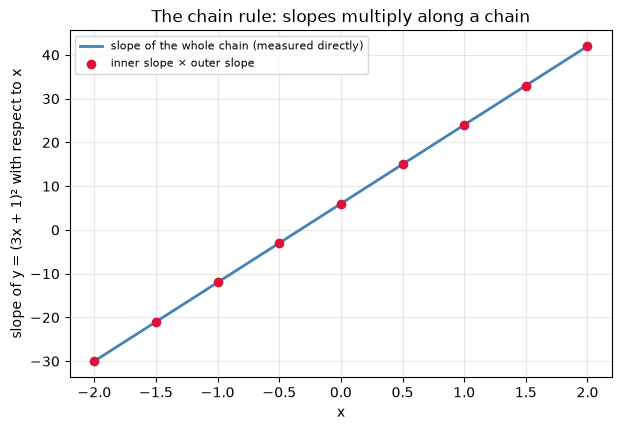

In [5]:
xs = np.linspace(-2, 2, 9)
direct = [numerical_slope(f_of_g, x) for x in xs]
multiplied = [numerical_slope(g, x) * numerical_slope(f, g(x)) for x in xs]

plt.plot(
    xs,
    direct,
    color="steelblue",
    linewidth=2,
    label="slope of the whole chain (measured directly)",
)
plt.scatter(xs, multiplied, color="crimson", zorder=3, label="inner slope × outer slope")
plt.xlabel("x")
plt.ylabel("slope of y = (3x + 1)² with respect to x")
plt.title("The chain rule: slopes multiply along a chain")
plt.legend(fontsize=8)
plt.show()

### When there's more than one road

In a network, one number can affect the loss along **more than one path**.
A single input feeds *both* hidden neurons, and both of them feed the output.
Back to the gears: suppose gear A drives C through two separate gear trains,
one that makes C turn 6 times and another that makes it turn 4 times. The
two effects **add**, so C turns $6 + 4 = 10$ times.

So there are two rules of thumb:

- **Along** a path, slopes **multiply**.
- **Across** separate paths, the results **add**.

That's the whole idea behind backpropagation. The next section says it
precisely.

## 4. The chain rule, formally

This section is the mathematician's version of Section 3. Nothing new
happens here. It gives exact names and notation to what the gears already
showed us, so that we can write the backward pass precisely.

### Notation: the derivative

In Lessons 1–3 we used the word **slope**, and measured it by nudging. The
formal name is the **derivative**, and it is defined as the value the nudging
estimate settles down to as the nudge gets smaller and smaller:

$$ f'(x) \;=\; \lim_{h \to 0} \frac{f(x + h) - f(x)}{h} $$

Read "$\lim_{h \to 0}$" as "what this ratio approaches as $h$ shrinks toward
zero." That's the `numerical_slope` idea, taken to its limit. If this limit
exists, $f$ is **differentiable** at $x$ (Lesson 3's word). There are two
common ways to write the derivative, and they mean the same thing:

| Notation | Read aloud as | Named after |
|---|---|---|
| $f'(x)$ | "f prime of x" | Lagrange |
| $\dfrac{dy}{dx}$ (when $y = f(x)$) | "dee y by dee x", i.e. the rate of change of $y$ as $x$ changes | Leibniz |

$\frac{dy}{dx}$ is **not** a fraction you can simplify. It's a single
symbol that means "the slope of $y$ with respect to $x$." (It does
*behave* a lot like a fraction, which is exactly why the chain rule looks so
natural in this notation.)

### The chain rule (one path)

> **Chain rule.** Let $u = g(x)$ and $y = f(u)$, so that $y = f(g(x))$.
> If $g$ is differentiable at $x$, and $f$ is differentiable at $g(x)$,
> then the combined function $f(g(x))$ is differentiable at $x$, and
>
> $$ \frac{d}{dx}\, f\bigl(g(x)\bigr) \;=\; f'\bigl(g(x)\bigr)\cdot g'(x) $$
>
> or, in Leibniz notation,
>
> $$ \frac{dy}{dx} \;=\; \frac{dy}{du}\cdot\frac{du}{dx}. $$

Each piece of the formula lines up with the gears:

- $g'(x)$ is the inner gear ratio: how fast $u$ moves when $x$ moves.
- $f'(g(x))$ is the outer gear ratio, **measured where the inner function
  actually landed**. That's why we measured $f$'s slope at $u = 7$, not
  $x = 2$, in Section 3.
- The **"if ... differentiable"** condition is Lesson 3's lesson in formal
  form. If any link in the chain has no slope (like the step function's
  jump), the rule has nothing to multiply and the chain breaks.

Checking Section 3's example exactly: $g(x) = 3x+1$ has $g'(x) = 3$, and
$f(u) = u^2$ has $f'(u) = 2u$. So

$$ \frac{dy}{dx} = f'(g(x))\cdot g'(x) = 2(3x+1)\cdot 3 = 6(3x+1), $$

which at $x = 2$ is $6 \times 7 = 42$, matching the measured value.

### Longer chains

The rule applies again at every link. For $x \to u \to v \to y$:

$$ \frac{dy}{dx} = \frac{dy}{dv}\cdot\frac{dv}{du}\cdot\frac{du}{dx}. $$

A neural network is exactly such a chain: weight → weighted sum $z$ →
activation → next weighted sum → ... → prediction → loss.

### Many inputs: partial derivatives

The loss depends on *many* numbers at once (9 of them for our small
network). When a function has several inputs, we take the slope with respect
to **one** input while holding all the others fixed. That's called a
**partial derivative**, written with a curly $\partial$ ("partial") instead
of $d$:

$$ \frac{\partial L}{\partial w} \quad = \quad \text{slope of } L \text{ when only } w \text{ is nudged.} $$

It's the same nudging idea as before: change one weight, leave every other
weight alone, and see how the loss responds. The list of all these partial
derivatives, one per weight, is the **gradient**. It's the "which way is
downhill" direction that gradient descent follows.

### The chain rule (many paths)

> **Multivariable chain rule.** Suppose $L$ depends on $w$ only through
> the intermediate quantities $u_1, u_2, \dots, u_k$, each of which depends on
> $w$, and all the functions involved are differentiable. Then
>
> $$ \frac{\partial L}{\partial w} \;=\; \sum_{j=1}^{k} \frac{\partial L}{\partial u_j}\cdot\frac{\partial u_j}{\partial w}
> \;=\; \frac{\partial L}{\partial u_1}\frac{\partial u_1}{\partial w} + \cdots + \frac{\partial L}{\partial u_k}\frac{\partial u_k}{\partial w}. $$

In words: **multiply along each path, then add up the paths**. These are the
two rules of thumb from Section 3's gears. The $\sum$ sign ("sigma")
just means "add these up for every $j$ from 1 to $k$."

Let's check the many-paths version numerically with a small example. Let
$w$ feed two intermediate values, $u_1 = 2w$ and $u_2 = w^2$, which are then
combined as $L = u_1 \cdot u_2$ (so $L = 2w^3$, whose slope is $6w^2$).

In [6]:
def L_of_w(w):
    u1 = 2 * w
    u2 = w**2
    return u1 * u2


w0 = 1.5
u1, u2 = 2 * w0, w0**2

# Each factor, written out by hand:
dL_du1, du1_dw = (
    u2,
    2,
)  # L = u1*u2, so nudging u1 changes L at rate u2; u1 = 2w has slope 2
dL_du2, du2_dw = u1, 2 * w0  # nudging u2 changes L at rate u1; u2 = w^2 has slope 2w

path_1 = dL_du1 * du1_dw
path_2 = dL_du2 * du2_dw

print(f"path through u1: {dL_du1} x {du1_dw} = {path_1}")
print(f"path through u2: {dL_du2} x {du2_dw} = {path_2}")
print(f"sum of paths   : {path_1 + path_2}")
print(f"measured slope : {numerical_slope(L_of_w, w0):.4f}")
print(f"exact (6w^2)   : {6 * w0**2}")

path through u1: 2.25 x 2 = 4.5
path through u2: 3.0 x 3.0 = 9.0
sum of paths   : 13.5
measured slope : 13.5000
exact (6w^2)   : 13.5


Multiplying along each path and adding the two paths gives exactly the
measured slope. That's all the calculus backpropagation needs. The rest of
this lesson applies these two rules to a neural network, one link at a time.

## 5. Estimating slopes by nudging, and why it's too slow

Before using the chain rule, let's try the brute-force approach we already
know from Lesson 3. For every one of the 9 numbers in our network, nudge it
up a tiny bit, nudge it down a tiny bit, rerun the whole network each time,
and see how the loss changed.

In [7]:
def loss_of(params):
    "Loss of the network on XOR for a given (W1, b1, W2, b2)."
    _, prediction = forward_pass(inputs, *params)
    return mse(prediction, Y)


def numerical_gradient(params, h=1e-5):
    "Slope of the loss w.r.t. every single number in params, found by nudging each one."
    grads = []
    forward_passes = 0
    for p in params:
        grad = np.zeros_like(p)
        for idx in np.ndindex(p.shape):  # visit every entry of this array in turn
            original = p[idx]
            p[idx] = original + h
            loss_up = loss_of(params)
            p[idx] = original - h
            loss_down = loss_of(params)
            p[idx] = original  # put it back exactly as it was
            grad[idx] = (loss_up - loss_down) / (2 * h)
            forward_passes += 2
        grads.append(grad)
    return grads, forward_passes


params = [W1.copy(), b1.copy(), W2.copy(), b2.copy()]
num_grads, n_passes = numerical_gradient(params)

for name, grad in zip(["dW1", "db1", "dW2", "db2"], num_grads):
    print(f"{name} =\n{np.round(grad, 5)}\n")
print(f"Forward passes needed: {n_passes}")

dW1 =
[[ 0.00227 -0.00085]
 [ 0.0016  -0.00097]]

db1 =
[ 0.0024  -0.00151]

dW2 =
[[-0.01076]
 [-0.00853]]

db2 =
[-0.01713]

Forward passes needed: 18


It works, and it gives us all 9 slopes. The cost is **2 full forward passes
per number**. For our 9-number network that's 18 passes, which is nothing.
Now let's see how the cost grows with the size of the network:

In [8]:
examples = {
    "our XOR network": 9,
    "Lesson 4-style net, 100 hidden neurons": 2 * 100 + 100 + 100 * 1 + 1,
    "small image classifier": 100_000,
    "a modern large language model": 100_000_000_000,
}

print(f"{'network':<42} {'parameters':>18} {'forward passes per step':>25}")
for name, n in examples.items():
    print(f"{name:<42} {n:>18,} {2 * n:>25,}")

network                                            parameters   forward passes per step
our XOR network                                             9                        18
Lesson 4-style net, 100 hidden neurons                    401                       802
small image classifier                                100,000                   200,000
a modern large language model                 100,000,000,000           200,000,000,000


A large language model would need **two hundred billion** forward passes
just to take **one** step of gradient descent, and training takes millions
of steps. Nudging is useful for *checking* slopes, and we'll use it that
way, but it's hopeless for *training*.

Backpropagation, as we're about to see, gets **every** slope from **one
forward pass plus one backward pass**, no matter how many weights there
are. Let's see how.

## 6. Backpropagation by hand, on a tiny network

To see every step clearly, shrink the network to the smallest thing that
still has a hidden layer: **1 input, 1 hidden neuron, 1 output neuron**, and
one training example. Every quantity is now a single number, so no matrices
yet.

**Forward pass** (left to right). Each line uses only the lines above it:

$$
\begin{aligned}
z_1 &= w_1 x + b_1 && \text{hidden neuron's weighted sum} \\
h &= \sigma(z_1) && \text{hidden neuron's output} \\
z_2 &= w_2 h + b_2 && \text{output neuron's weighted sum} \\
\hat{y} &= \sigma(z_2) && \text{prediction} \\
L &= (\hat{y} - y)^2 && \text{loss (squared error, one example)}
\end{aligned}
$$

Here's that chain drawn as a diagram. Each box is one quantity, and each
arrow is one link in the chain.

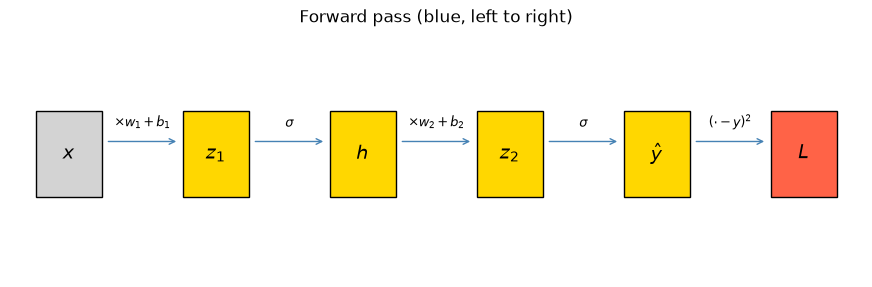

In [9]:
def draw_chain_diagram(forward_values=None, backward_values=None):
    "Draw x -> z1 -> h -> z2 -> y_hat -> L, optionally labelled with values and slopes."
    nodes = ["x", "z1", "h", "z2", "y_hat", "L"]
    labels = {
        "x": "$x$",
        "z1": "$z_1$",
        "h": "$h$",
        "z2": "$z_2$",
        "y_hat": "$\\hat{y}$",
        "L": "$L$",
    }
    link_labels = [
        "$\\times w_1 + b_1$",
        "$\\sigma$",
        "$\\times w_2 + b_2$",
        "$\\sigma$",
        "$(\\cdot - y)^2$",
    ]

    fig, ax = plt.subplots(figsize=(11, 3.2))
    xs = np.arange(len(nodes)) * 2.0

    for i, name in enumerate(nodes):
        color = "lightgray" if name == "x" else "tomato" if name == "L" else "gold"
        ax.add_patch(plt.Rectangle((xs[i] - 0.45, -0.35), 0.9, 0.7, color=color, ec="black", zorder=3))
        ax.text(xs[i], 0, labels[name], ha="center", va="center", fontsize=14, zorder=4)
        if forward_values is not None and name in forward_values:
            ax.text(
                xs[i],
                0.6,
                f"{forward_values[name]:.3f}",
                ha="center",
                color="steelblue",
                fontsize=10,
            )
        if backward_values is not None and name in backward_values:
            ax.text(
                xs[i],
                -0.7,
                f"∂L/∂{name} = {backward_values[name]:.3f}",
                ha="center",
                color="crimson",
                fontsize=9,
            )

    for i in range(len(nodes) - 1):
        ax.annotate(
            "",
            xy=(xs[i + 1] - 0.5, 0.1),
            xytext=(xs[i] + 0.5, 0.1),
            arrowprops=dict(arrowstyle="->", color="steelblue"),
        )
        ax.text((xs[i] + xs[i + 1]) / 2, 0.22, link_labels[i], ha="center", fontsize=9)
        if backward_values is not None:
            ax.annotate(
                "",
                xy=(xs[i] + 0.5, -0.12),
                xytext=(xs[i + 1] - 0.5, -0.12),
                arrowprops=dict(arrowstyle="->", color="crimson"),
            )

    ax.set_xlim(-0.8, xs[-1] + 0.8)
    ax.set_ylim(-1.0, 1.0)
    ax.axis("off")
    title = "Forward pass (blue, left to right)"
    if backward_values is not None:
        title += "   ·   backward pass (red, right to left)"
    ax.set_title(title)
    return fig


draw_chain_diagram()
plt.show()

Let's pick some starting numbers and run the forward pass, writing down
**every** intermediate value. We'll need all of them on the way back.

In [10]:
# One training example, and a starting guess for the 4 parameters.
x, y = 1.0, 1.0
w1, b1_tiny = 0.5, 0.0
w2, b2_tiny = -1.0, 0.5

# Forward pass -- save every intermediate value.
z1 = w1 * x + b1_tiny
h = sigmoid(z1)
z2 = w2 * h + b2_tiny
y_hat = sigmoid(z2)
L = (y_hat - y) ** 2

print("Forward pass:")
print(f"  z1    = w1*x + b1  = {w1}*{x} + {b1_tiny}  = {z1:.4f}")
print(f"  h     = sigmoid(z1)              = {h:.4f}")
print(f"  z2    = w2*h + b2  = {w2}*{h:.4f} + {b2_tiny} = {z2:.4f}")
print(f"  y_hat = sigmoid(z2)              = {y_hat:.4f}")
print(f"  L     = (y_hat - y)^2            = {L:.4f}   (target y = {y})")

Forward pass:
  z1    = w1*x + b1  = 0.5*1.0 + 0.0  = 0.5000
  h     = sigmoid(z1)              = 0.6225
  z2    = w2*h + b2  = -1.0*0.6225 + 0.5 = -0.1225
  y_hat = sigmoid(z2)              = 0.4694
  L     = (y_hat - y)^2            = 0.2815   (target y = 1.0)


The prediction is about 0.5 when the target is 1, so there's clearly room
to improve.

**Backward pass** (right to left). We want $\frac{\partial L}{\partial w_1}$,
$\frac{\partial L}{\partial b_1}$, $\frac{\partial L}{\partial w_2}$ and
$\frac{\partial L}{\partial b_2}$. We start at the loss and walk back one
link at a time. At each box we compute "how much does $L$ change when this
box changes", using the answer from the box just to its right, which is the
relay coach's method. The only single-link slopes we need are:

| link | its slope | why |
|---|---|---|
| $L = (\hat{y}-y)^2$ | $\frac{\partial L}{\partial \hat{y}} = 2(\hat{y} - y)$ | Lesson 1's practice hill, shifted by $y$ |
| $\hat{y} = \sigma(z_2)$ | $\frac{\partial \hat{y}}{\partial z_2} = \sigma'(z_2)$ | Lesson 3's `sigmoid_grad` |
| $z_2 = w_2 h + b_2$ | $\frac{\partial z_2}{\partial w_2} = h, \quad \frac{\partial z_2}{\partial b_2} = 1, \quad \frac{\partial z_2}{\partial h} = w_2$ | straight lines: slope is just the multiplier |
| $h = \sigma(z_1)$ | $\frac{\partial h}{\partial z_1} = \sigma'(z_1)$ | Lesson 3's `sigmoid_grad` again |
| $z_1 = w_1 x + b_1$ | $\frac{\partial z_1}{\partial w_1} = x, \quad \frac{\partial z_1}{\partial b_1} = 1$ | straight lines again |

Now chain them together, starting from the loss end:

In [11]:
print("Backward pass (each line reuses the line above it):\n")

dL_dyhat = 2 * (y_hat - y)
print(f"  dL/dy_hat = 2*(y_hat - y)                  = {dL_dyhat:.4f}")

dL_dz2 = dL_dyhat * sigmoid_grad(z2)
print(f"  dL/dz2    = dL/dy_hat * sigmoid'(z2)       = {dL_dz2:.4f}")

# z2 = w2*h + b2 has three inputs: w2, b2 and h. One slope for each.
dL_dw2 = dL_dz2 * h
dL_db2 = dL_dz2 * 1
dL_dh = dL_dz2 * w2
print(f"  dL/dw2    = dL/dz2 * h                     = {dL_dw2:.4f}")
print(f"  dL/db2    = dL/dz2 * 1                     = {dL_db2:.4f}")
print(f"  dL/dh     = dL/dz2 * w2                    = {dL_dh:.4f}")
print("              ^ the blame passed back to the hidden neuron")

dL_dz1 = dL_dh * sigmoid_grad(z1)
print(f"  dL/dz1    = dL/dh * sigmoid'(z1)           = {dL_dz1:.4f}")

dL_dw1 = dL_dz1 * x
dL_db1 = dL_dz1 * 1
print(f"  dL/dw1    = dL/dz1 * x                     = {dL_dw1:.4f}")
print(f"  dL/db1    = dL/dz1 * 1                     = {dL_db1:.4f}")

Backward pass (each line reuses the line above it):

  dL/dy_hat = 2*(y_hat - y)                  = -1.0612
  dL/dz2    = dL/dy_hat * sigmoid'(z2)       = -0.2643
  dL/dw2    = dL/dz2 * h                     = -0.1645
  dL/db2    = dL/dz2 * 1                     = -0.2643
  dL/dh     = dL/dz2 * w2                    = 0.2643
              ^ the blame passed back to the hidden neuron
  dL/dz1    = dL/dh * sigmoid'(z1)           = 0.0621
  dL/dw1    = dL/dz1 * x                     = 0.0621
  dL/db1    = dL/dz1 * 1                     = 0.0621


Written out in full, the slope for the hidden weight $w_1$ is a chain of
five factors, one per link, exactly as the chain rule promised:

$$
\frac{\partial L}{\partial w_1}
= \underbrace{2(\hat{y}-y)}_{\partial L/\partial \hat{y}}
\cdot \underbrace{\sigma'(z_2)}_{\partial \hat{y}/\partial z_2}
\cdot \underbrace{w_2}_{\partial z_2/\partial h}
\cdot \underbrace{\sigma'(z_1)}_{\partial h/\partial z_1}
\cdot \underbrace{x}_{\partial z_1/\partial w_1}
$$

Two things make backpropagation efficient:

1. **We never recompute a product.** $\frac{\partial L}{\partial z_2}$ was
   computed once and reused three times (for $w_2$, $b_2$ and $h$).
   $\frac{\partial L}{\partial z_1}$ was computed once and reused for both
   $w_1$ and $b_1$. In a big network, one layer's blame is reused by every
   weight feeding into that layer.
2. **We reused the forward pass.** $h$, $z_1$ and $z_2$ were already saved,
   so the backward pass only multiplies numbers we already have.

Here's the same diagram with both passes filled in:

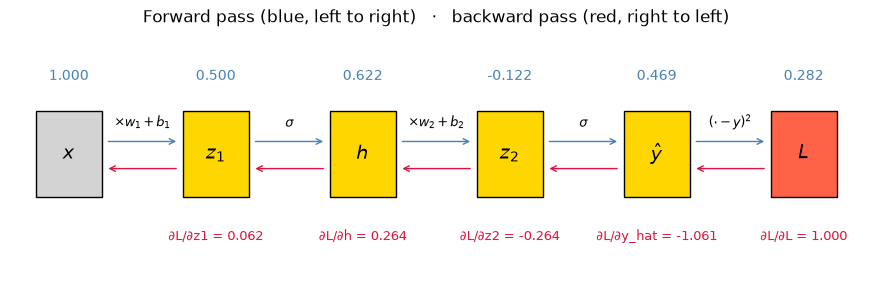

In [12]:
draw_chain_diagram(
    forward_values={"x": x, "z1": z1, "h": h, "z2": z2, "y_hat": y_hat, "L": L},
    backward_values={
        "z1": dL_dz1,
        "h": dL_dh,
        "z2": dL_dz2,
        "y_hat": dL_dyhat,
        "L": 1.0,
    },
)
plt.show()

(The loss's slope with respect to itself is 1, since nudging $L$ changes
$L$ by exactly the same amount. That's where the backward pass starts.)

**Now the check.** If the chain rule is right, nudging each parameter should
give the same four numbers:

In [13]:
def tiny_loss(w1, b1, w2, b2):
    "Loss of the 1-1-1 network on our single example."
    h = sigmoid(w1 * x + b1)
    y_hat = sigmoid(w2 * h + b2)
    return (y_hat - y) ** 2


nudged = {
    "w1": numerical_slope(lambda v: tiny_loss(v, b1_tiny, w2, b2_tiny), w1),
    "b1": numerical_slope(lambda v: tiny_loss(w1, v, w2, b2_tiny), b1_tiny),
    "w2": numerical_slope(lambda v: tiny_loss(w1, b1_tiny, v, b2_tiny), w2),
    "b2": numerical_slope(lambda v: tiny_loss(w1, b1_tiny, w2, v), b2_tiny),
}
backprop = {"w1": dL_dw1, "b1": dL_db1, "w2": dL_dw2, "b2": dL_db2}

print(f"{'param':>6} {'backprop':>10} {'nudging':>10}")
for name in backprop:
    print(f"{name:>6} {backprop[name]:>10.5f} {nudged[name]:>10.5f}")

 param   backprop    nudging
    w1    0.06211    0.06211
    b1    0.06211    0.06211
    w2   -0.16451   -0.16451
    b2   -0.26430   -0.26430


They agree to every decimal place shown. And now the payoff: take **one**
gradient descent step with these slopes, exactly like Lesson 1, and check
that the loss went down.

In [14]:
learning_rate = 1.0

w1_new = w1 - learning_rate * dL_dw1
b1_new = b1_tiny - learning_rate * dL_db1
w2_new = w2 - learning_rate * dL_dw2
b2_new = b2_tiny - learning_rate * dL_db2

print(f"loss before the step: {tiny_loss(w1, b1_tiny, w2, b2_tiny):.4f}")
print(f"loss after the step : {tiny_loss(w1_new, b1_new, w2_new, b2_new):.4f}")

loss before the step: 0.2815
loss after the step : 0.1876


One step downhill. Notice the signs from the backward pass: $w_2$'s slope
was negative, meaning "increasing $w_2$ lowers the loss," so gradient descent
increased it. Every parameter moved in the direction its own slope said
was downhill.

## 7. Scaling up: the backward pass in matrix form

Our real XOR network has 2 inputs, 2 hidden neurons, 1 output, and **4**
training examples processed together. It follows the same chain of links as
the tiny network. The only difference is that each quantity is now a
**matrix** (one row per example, one column per neuron), just like Lesson 4's
forward pass. Here are the two passes side by side:

| Forward pass (Lesson 4) | Backward pass (new) |
|---|---|
| $Z_1 = X W_1 + b_1$ | $\dfrac{\partial L}{\partial W_1} = X^{\top} \, dZ_1, \qquad \dfrac{\partial L}{\partial b_1} = \text{sum of rows of } dZ_1$ |
| $A_1 = \sigma(Z_1)$ | $dZ_1 = dA_1 \odot \sigma'(Z_1)$ |
| $Z_2 = A_1 W_2 + b_2$ | $dA_1 = dZ_2 \, W_2^{\top}, \quad \dfrac{\partial L}{\partial W_2} = A_1^{\top} \, dZ_2, \quad \dfrac{\partial L}{\partial b_2} = \text{sum of rows of } dZ_2$ |
| $\hat{Y} = A_2 = \sigma(Z_2)$ | $dZ_2 = dA_2 \odot \sigma'(Z_2)$ |
| $L = \frac{1}{n}\sum (A_2 - Y)^2$ | $dA_2 = \frac{2}{n}(A_2 - Y)$ |

Read the backward column **from the bottom up**. We use the short name
$dZ_2$ for $\frac{\partial L}{\partial Z_2}$, meaning the loss's slope with
respect to every entry of $Z_2$, and the same for the others. Each row is the
matrix version of a line from Section 6's backward pass:

- $\odot$ means **multiply entry by entry** (in NumPy, just `*`). It's the
  "$\cdot\, \sigma'(z)$" step, applied to every neuron and every example at
  once.
- $W_2^{\top}$ (the **transpose**, `W2.T` in NumPy) flips a matrix so its rows
  become columns. In the forward pass, $W_2$ carried each hidden neuron's
  signal **forward** to the output. $W_2^{\top}$ carries the output's blame
  **backward** to each hidden neuron, along the same connections in reverse.
  It's the matrix version of "$\frac{\partial L}{\partial h} = \frac{\partial L}{\partial z_2}\cdot w_2$".
- $A_1^{\top}\,dZ_2$ and $X^{\top}\,dZ_1$ are the matrix versions of
  "$\cdot\, h$" and "$\cdot\, x$". Matrix multiplication multiplies and then
  **adds up across the 4 examples**. That's the multivariable chain rule's
  sum: each weight affects the loss through every training example, so its
  slope adds up the blame from all four paths.
- The bias slopes add up $dZ$ down its rows for the same reason: the slope of
  $z$ with respect to a bias is 1 for every example.

In code, each row of the table becomes one line:

In [15]:
def backward_pass(X, Y, W1, b1, W2, b2):
    "Slopes of the MSE loss w.r.t. W1, b1, W2, b2 for a 2-layer sigmoid network."
    n = len(X)

    # Forward pass, keeping every intermediate value for the way back.
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Backward pass: start at the loss, walk back one link at a time.
    dA2 = 2 * (A2 - Y) / n  # loss -> prediction
    dZ2 = dA2 * sigmoid_grad(Z2)  # prediction -> output neuron's z
    dW2 = A1.T @ dZ2  # output z -> output weights (summed over examples)
    db2 = dZ2.sum(axis=0)  # output z -> output bias
    dA1 = dZ2 @ W2.T  # output z -> hidden outputs (blame passed back)
    dZ1 = dA1 * sigmoid_grad(Z1)  # hidden outputs -> hidden z
    dW1 = X.T @ dZ1  # hidden z -> hidden weights
    db1 = dZ1.sum(axis=0)  # hidden z -> hidden biases

    return [dW1, db1, dW2, db2]

The chain rule doesn't care whether the numbers are single values or
matrices, so this should agree with Section 5's slow nudging on all 9
parameters of the random network from Section 1. This kind of check is
called a **gradient check**. Real machine-learning engineers use it to test
their own backward passes.

In [16]:
bp_grads = backward_pass(inputs, Y, W1, b1, W2, b2)

print(f"{'param':>6} {'max difference, backprop vs nudging':>38}")
for name, bp, num in zip(["dW1", "db1", "dW2", "db2"], bp_grads, num_grads):
    print(f"{name:>6} {np.max(np.abs(bp - num)):>38.2e}")

 param    max difference, backprop vs nudging
   dW1                               2.02e-12
   db1                               2.88e-12
   dW2                               8.53e-13
   db2                               2.75e-13


The differences are tiny, around $10^{-11}$ or smaller, which is just
rounding noise from the nudges. The two methods agree. Now compare the
**cost** of the two on a bigger network: 100 hidden neurons, so 401
parameters:

In [17]:
rng_big = np.random.default_rng(1)
big_params = [
    rng_big.normal(0, 1, size=(2, 100)),
    np.zeros(100),
    rng_big.normal(0, 1, size=(100, 1)),
    np.zeros(1),
]

start = time.perf_counter()
for _ in range(10):
    numerical_gradient(big_params)
nudge_time = (time.perf_counter() - start) / 10

start = time.perf_counter()
for _ in range(10):
    backward_pass(inputs, Y, *big_params)
backprop_time = (time.perf_counter() - start) / 10

print(f"Nudging        : {nudge_time * 1000:8.3f} ms per gradient")
print(f"Backpropagation: {backprop_time * 1000:8.3f} ms per gradient")
print(f"Backpropagation is roughly {nudge_time / backprop_time:,.0f}x faster here,")
print("and the gap grows with the size of the network.")

Nudging        :   14.148 ms per gradient
Backpropagation:    0.044 ms per gradient
Backpropagation is roughly 320x faster here,
and the gap grows with the size of the network.


## 8. Training XOR from scratch

We now have everything Lesson 1's gradient descent loop needs. Every epoch:

1. `backward_pass` computes the slopes of the loss for all 9 parameters
   (it does a forward pass internally).
2. Every parameter takes a small step **downhill**: `param -= learning_rate * slope`.

That's the whole training algorithm. We'll also save a few snapshots of the
network along the way so we can watch the decision boundary change.

 x1  x2  prediction  rounded  target
  0   0       0.018        0       0
  0   1       0.983        1       1
  1   0       0.979        1       1
  1   1       0.016        0       0

Final loss: 0.00032


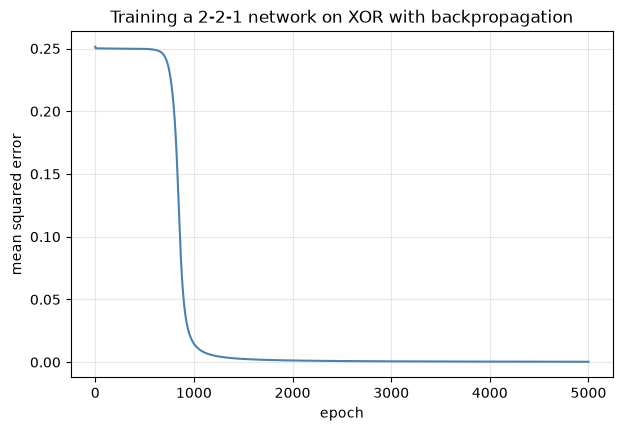

In [18]:
def train_mlp(X, Y, n_hidden=2, learning_rate=2.0, n_epochs=5000, seed=0, snapshot_epochs=()):
    "Train a 2-layer sigmoid network with backpropagation + gradient descent."
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, size=(X.shape[1], n_hidden))
    b1 = np.zeros(n_hidden)
    W2 = rng.normal(0, 1, size=(n_hidden, 1))
    b2 = np.zeros(1)

    loss_history = []
    snapshots = {}

    for epoch in range(n_epochs + 1):
        if epoch in snapshot_epochs:
            snapshots[epoch] = (W1.copy(), b1.copy(), W2.copy(), b2.copy())

        _, prediction = forward_pass(X, W1, b1, W2, b2)
        loss_history.append(mse(prediction, Y))

        dW1, db1, dW2, db2 = backward_pass(X, Y, W1, b1, W2, b2)
        W1 = W1 - learning_rate * dW1
        b1 = b1 - learning_rate * db1
        W2 = W2 - learning_rate * dW2
        b2 = b2 - learning_rate * db2

    return (W1, b1, W2, b2), loss_history, snapshots


snapshot_epochs = [0, 200, 500, 1000, 2000, 5000]
trained, loss_history, snapshots = train_mlp(inputs, Y, snapshot_epochs=snapshot_epochs)

_, final_prediction = forward_pass(inputs, *trained)
print(f"{'x1':>3} {'x2':>3} {'prediction':>11} {'rounded':>8} {'target':>7}")
for x_row, pred, target in zip(inputs, final_prediction.flatten(), xor_labels):
    print(f"{x_row[0]:>3} {x_row[1]:>3} {pred:>11.3f} {round(pred):>8} {target:>7}")
print(f"\nFinal loss: {loss_history[-1]:.5f}")

plt.plot(loss_history, color="steelblue")
plt.xlabel("epoch")
plt.ylabel("mean squared error")
plt.title("Training a 2-2-1 network on XOR with backpropagation")
plt.show()

**The network learned XOR by itself**, starting from random weights with no
hand-picked OR/NAND/AND gates. The loss curve has an interesting shape:
a long, nearly flat stretch at the start, then a sudden drop. During the
flat stretch the network is slowly working out *how* to split the problem
between its two hidden neurons. Once it finds a workable split, the loss
falls quickly.

Let's watch the decision boundary change at each snapshot, shaded the same
way as in Lesson 4:

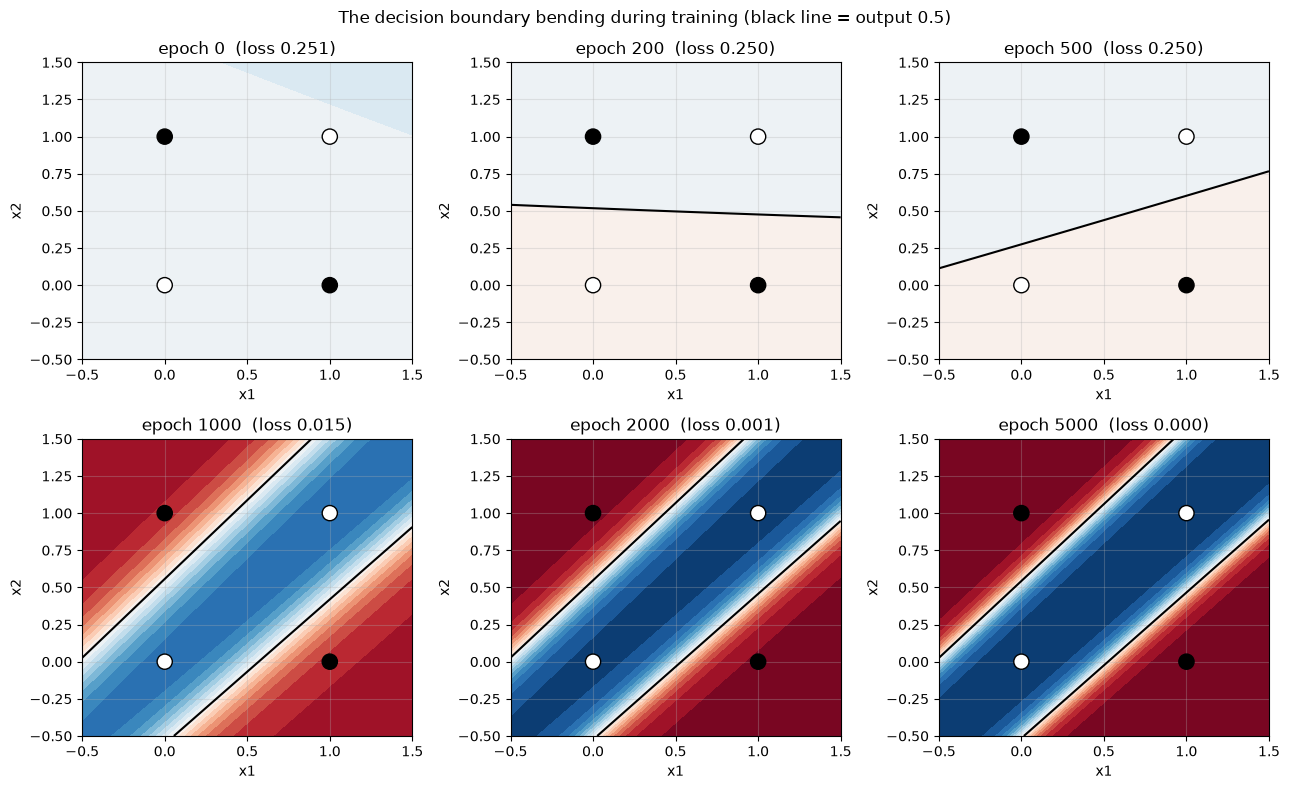

In [19]:
def plot_network_surface(W1, b1, W2, b2, title, ax=None):
    "Shade the input space by the network's output, and scatter the 4 XOR points."
    if ax is None:
        _, ax = plt.subplots()

    grid = np.linspace(-0.5, 1.5, 200)
    X1, X2 = np.meshgrid(grid, grid)
    grid_points = np.column_stack([X1.ravel(), X2.ravel()])
    _, Z = forward_pass(grid_points, W1, b1, W2, b2)
    Z = Z.reshape(X1.shape)

    ax.contourf(X1, X2, Z, levels=np.linspace(0, 1, 21), cmap="RdBu_r")
    ax.contour(X1, X2, Z, levels=[0.5], colors="black", linewidths=1.5)

    colors = np.where(xor_labels == 1, "black", "white")
    ax.scatter(inputs[:, 0], inputs[:, 1], c=colors, s=120, zorder=3, edgecolor="black")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    return ax


fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, epoch in zip(axes.flat, snapshot_epochs):
    plot_network_surface(*snapshots[epoch], f"epoch {epoch}  (loss {loss_history[epoch]:.3f})", ax=ax)
plt.suptitle("The decision boundary bending during training (black line = output 0.5)")
plt.tight_layout()
plt.show()

At epoch 0 the random network draws a boundary that has nothing to do with
XOR. Over the first few hundred epochs it slowly tilts and shifts. Then,
around the time the loss curve drops, it splits into **two parallel lines**
with a diagonal band between them. In this run the two white points
(label 0) sit inside the band and the two black points (label 1) sit
outside it, one on each side. That's the reverse of Lesson 4's
hand-designed network, which put the black points inside, but it's the
same trick: two straight lines working together. This time gradient
descent found it without our help.

## 9. What did the hidden layer invent?

In Lesson 4 we *chose* the hidden neurons to compute OR and NAND. Nobody told
this network to do that. So what did its two hidden neurons end up
computing? Let's look at each one on its own, then plot the hidden layer's
output space the same way Lesson 4 did.

 x1  x2      h1      h2   XOR
  0   0   0.957   0.048     0
  0   1   1.000   0.928     1
  1   0   0.046   0.000     1
  1   1   0.962   0.039     0


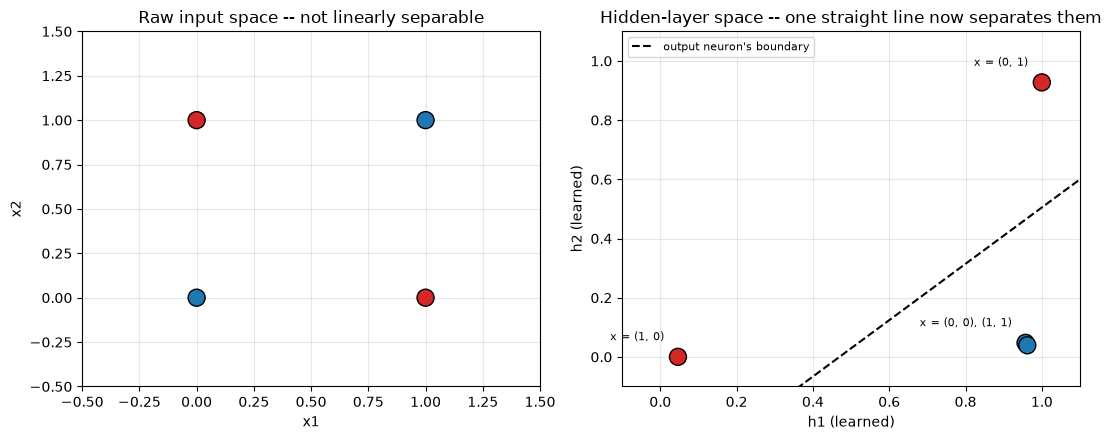

In [20]:
W1_t, b1_t, W2_t, b2_t = trained
hidden_out, _ = forward_pass(inputs, *trained)

print(f"{'x1':>3} {'x2':>3} {'h1':>7} {'h2':>7} {'XOR':>5}")
for x_row, h_row, target in zip(inputs, hidden_out, xor_labels):
    print(f"{x_row[0]:>3} {x_row[1]:>3} {h_row[0]:>7.3f} {h_row[1]:>7.3f} {target:>5}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
colors = np.where(xor_labels == 1, "tab:red", "tab:blue")

ax1.scatter(inputs[:, 0], inputs[:, 1], c=colors, s=150, zorder=3, edgecolor="black")
ax1.set_xlim(-0.5, 1.5)
ax1.set_ylim(-0.5, 1.5)
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.set_title("Raw input space -- not linearly separable")

ax2.scatter(hidden_out[:, 0], hidden_out[:, 1], c=colors, s=150, zorder=3, edgecolor="black")
# Two inputs can land almost on top of each other in hidden space -- group
# them so each spot gets one label listing every input that landed there.
groups = {}
for x_row, h_row in zip(inputs, hidden_out):
    key = tuple(np.round(h_row, 1))
    groups.setdefault(key, {"at": h_row, "sources": []})
    groups[key]["sources"].append(str(tuple(int(v) for v in x_row)))
for info in groups.values():
    text = "x = " + ", ".join(info["sources"])
    ax2.annotate(
        text,
        info["at"],
        textcoords="offset points",
        xytext=(-10, 12),
        fontsize=8,
        ha="right",
    )

# The output neuron's boundary is where its weighted sum is 0 (output exactly 0.5):
#   W2[0]*h1 + W2[1]*h2 + b2 = 0   ->   h2 = -(W2[0]*h1 + b2) / W2[1]
h1_line = np.linspace(-0.1, 1.1, 50)
h2_line = -(W2_t[0, 0] * h1_line + b2_t[0]) / W2_t[1, 0]
ax2.plot(h1_line, h2_line, "k--", label="output neuron's boundary")
ax2.set_xlim(-0.1, 1.1)
ax2.set_ylim(-0.1, 1.1)
ax2.set_xlabel("h1 (learned)")
ax2.set_ylabel("h2 (learned)")
ax2.set_title("Hidden-layer space -- one straight line now separates them")
ax2.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

Round each hidden column to 0 or 1 and read it as a truth table. In this
run (seed 0) the network did **not** reinvent Lesson 4's OR and NAND:

- $h_2$ fires only for $(0, 1)$, so it computes "$x_2$ AND NOT $x_1$".
- $h_1$ is switched off only for $(1, 0)$, so it computes "NOT ($x_1$ AND
  NOT $x_2$)".

Neither is a gate we met in Lesson 2, but both are linearly separable, so a
single neuron can compute each one. Rerun training with a different `seed`
and you'll usually get a different pair.

Either way, the right-hand plot shows the result that matters. The hidden
layer has **re-represented** the four points so that a single straight line,
drawn by the output neuron, separates the reds from the blues. That's the
same job Lesson 4's hand-built hidden layer did. Backpropagation found *a*
solution, not necessarily *our* solution, and that's normal. There are many
different sets of weights that solve XOR, and training ends up at whichever
one is downhill from where it started.

## 10. Things that go wrong

Backpropagation computes slopes exactly, but gradient descent can still
struggle with the landscape those slopes describe. Here are three problems
you'll meet again and again.

### Unlucky starting points

Lesson 1 showed that gradient descent can get stuck in a **local minimum**,
a valley that isn't the deepest one. Let's train the same network from 20
different random starting points (seeds) and see how many succeed:

Solved XOR from 16 of 20 random starting points.
Stuck seeds: [5, 6, 13, 18], final losses [0.168, 0.125, 0.125, 0.125]


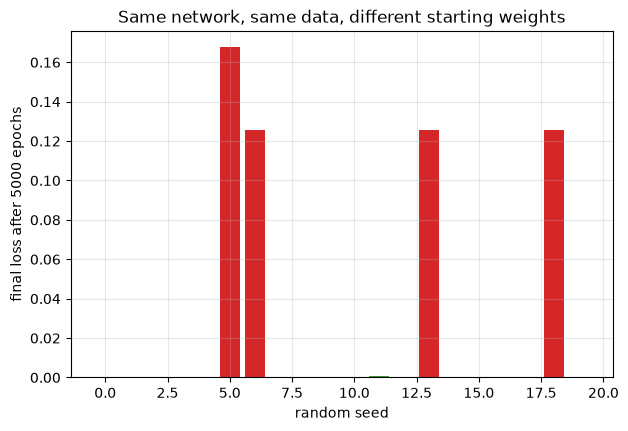

In [21]:
n_seeds = 20
final_losses = []
for seed in range(n_seeds):
    _, history, _ = train_mlp(inputs, Y, seed=seed)
    final_losses.append(history[-1])

final_losses = np.array(final_losses)
succeeded = final_losses < 0.05

print(f"Solved XOR from {succeeded.sum()} of {n_seeds} random starting points.")
stuck_seeds = np.flatnonzero(~succeeded).tolist()
stuck_losses = np.round(final_losses[~succeeded], 3).tolist()
print(f"Stuck seeds: {stuck_seeds}, final losses {stuck_losses}")

plt.bar(range(n_seeds), final_losses, color=np.where(succeeded, "tab:green", "tab:red"))
plt.xlabel("random seed")
plt.ylabel("final loss after 5000 epochs")
plt.title("Same network, same data, different starting weights")
plt.show()

Most starting points solve XOR, but a few don't. Those runs flatten out at
a loss of 0.125 or a bit higher and never get lower. Let's look inside one
of them:

Seed 6 predictions: [0.02  0.499 0.984 0.5  ]
Targets:               [0 1 1 0]


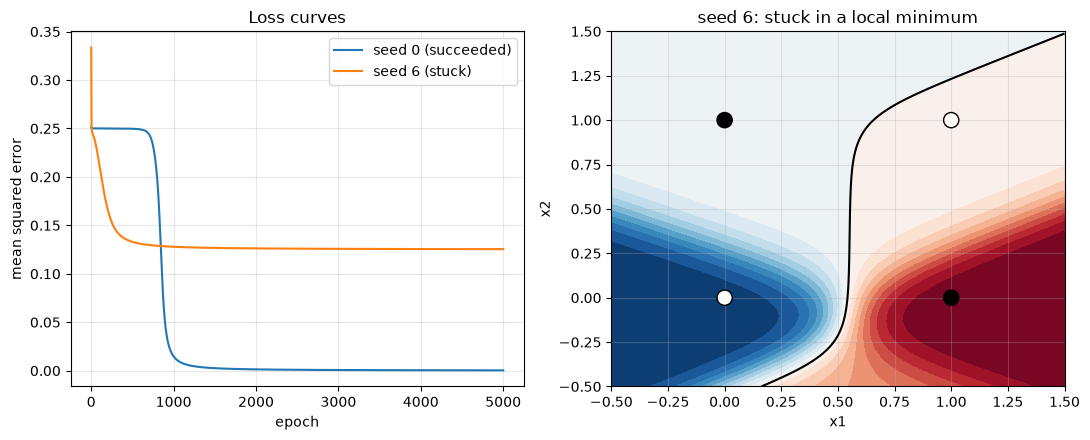

In [22]:
stuck_seed = 6  # one of the seeds stuck at a loss of about 0.125
stuck_params, stuck_history, _ = train_mlp(inputs, Y, seed=stuck_seed)
_, stuck_prediction = forward_pass(inputs, *stuck_params)

print(f"Seed {stuck_seed} predictions: {np.round(stuck_prediction.flatten(), 3)}")
print(f"Targets:               {xor_labels}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.plot(loss_history, label="seed 0 (succeeded)")
ax1.plot(stuck_history, label=f"seed {stuck_seed} (stuck)")
ax1.set_xlabel("epoch")
ax1.set_ylabel("mean squared error")
ax1.set_title("Loss curves")
ax1.legend()
plot_network_surface(*stuck_params, f"seed {stuck_seed}: stuck in a local minimum", ax=ax2)
plt.tight_layout()
plt.show()

The stuck network gets **two** of the four points confidently right and
gives up on the other two, sitting on the fence at 0.5 for both. That's
the "least bad" compromise available to it from where it is: every small
change that would help one of the fence-sitters hurts the other one just
as much. Getting out would mean temporarily making the loss worse, which is
an uphill move. Gradient descent never goes uphill, so it's trapped in a
**local minimum**.

The two standard fixes are simple: **try several random starts** and keep the
best, or **use more hidden neurons than strictly needed**. Extra neurons
give gradient descent more possible paths downhill, so it gets stuck less
often. (Exercise 2 asks you to test this.)

### Vanishing gradients

Look again at the chain for a hidden weight in Section 6. It contains a
$\sigma'(z)$ factor for **every layer** the blame passes through. Lesson 3
showed that sigmoid's slope is never bigger than **0.25**, and is much
smaller whenever $|z|$ is large. Multiplying many small numbers gives a
*very* small number:

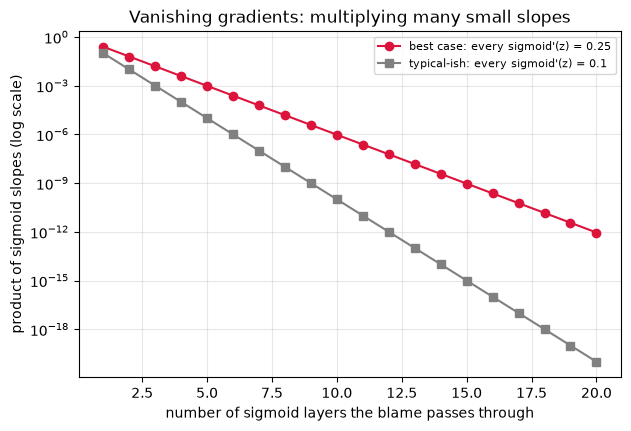

After 10 sigmoid layers, even the best case shrinks the blame by a
factor of 9.5e-07.


In [23]:
depths = np.arange(1, 21)

plt.semilogy(
    depths,
    0.25**depths,
    "o-",
    color="crimson",
    label="best case: every sigmoid'(z) = 0.25",
)
plt.semilogy(
    depths,
    0.1**depths,
    "s-",
    color="gray",
    label="typical-ish: every sigmoid'(z) = 0.1",
)
plt.xlabel("number of sigmoid layers the blame passes through")
plt.ylabel("product of sigmoid slopes (log scale)")
plt.title("Vanishing gradients: multiplying many small slopes")
plt.legend(fontsize=8)
plt.show()

print("After 10 sigmoid layers, even the best case shrinks the blame by a")
print(f"factor of {0.25**10:.1e}.")

After just 10 layers, even in the best case, the blame reaching the first
layer has been multiplied by about one in a million. The early layers'
weights barely move, so they barely learn. This is the **vanishing gradient
problem**, and it's the direct flip side of the chain rule: the same
multiplication that makes backpropagation work also makes long chains of
small slopes fade away.

It's one of the main reasons modern deep networks use **ReLU** (Lesson 3)
in their hidden layers. ReLU's slope is exactly **1** for every positive
input, so multiplying it along a chain doesn't shrink the blame.

### Learning rate, again

Lesson 1's warning still applies. Backpropagation tells us which way is
downhill, and the learning rate decides how big a step to take in that
direction.

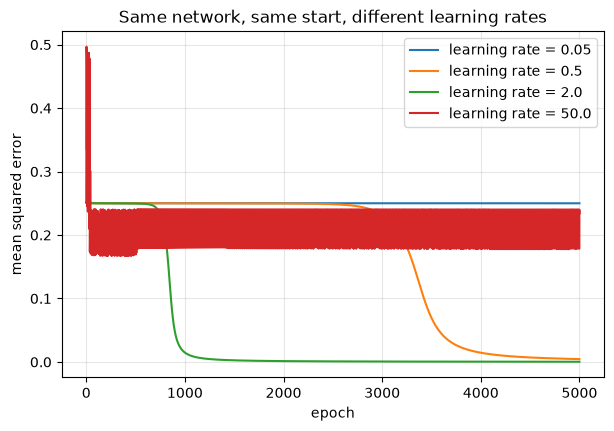

In [24]:
for lr in [0.05, 0.5, 2.0, 50.0]:
    _, history, _ = train_mlp(inputs, Y, learning_rate=lr, seed=0)
    plt.plot(history, label=f"learning rate = {lr}")

plt.xlabel("epoch")
plt.ylabel("mean squared error")
plt.title("Same network, same start, different learning rates")
plt.legend()
plt.show()

- **0.05** is too cautious. After 5000 epochs the network is still on the
  flat stretch at the start and hasn't really begun learning.
- **0.5** gets there eventually, well after 2.0 does.
- **50** is too reckless. Its first few giant steps throw the network into a
  poor region, where it ends up confidently wrong about one of the four
  points and stays there.

Choosing a learning rate is still a matter of trying a few values, exactly
as in Lesson 1.

## 11. Recap

- Training a network means finding the slope of the loss with respect to
  **every** weight and bias, then taking a gradient descent step. A hidden
  weight only affects the loss **through** later neurons, so its slope is a
  chain of effects.
- **The chain rule, intuitively:** rates multiply along a chain (gears,
  currency exchange). When there are several paths, the results add up.
- **The chain rule, formally:** if $g$ is differentiable at $x$ and $f$ is
  differentiable at $g(x)$, then
  $\frac{d}{dx} f(g(x)) = f'(g(x))\cdot g'(x)$, or
  $\frac{dy}{dx} = \frac{dy}{du}\cdot\frac{du}{dx}$. With several paths,
  $\frac{\partial L}{\partial w} = \sum_j \frac{\partial L}{\partial u_j}\frac{\partial u_j}{\partial w}$.
  The differentiability condition is why Lesson 3 insisted on smooth
  activation functions.
- **Nudging** each weight gives correct slopes, but costs 2 forward passes
  per weight, which is useless for real networks. It's still useful as a
  **gradient check**.
- **Backpropagation** applies the chain rule starting from the loss and
  working **backward**, reusing each layer's saved forward-pass values and
  the blame already computed for the next layer. One forward pass plus one
  backward pass gives **every** slope.
- In matrix form, the backward pass mirrors the forward pass: multiply entry
  by entry by $\sigma'(Z)$, send blame back through $W^{\top}$, and get
  weight slopes from $A_{\text{prev}}^{\top}\, dZ$.
- With backpropagation plus gradient descent, a 2-2-1 network **learned XOR
  from random weights**, inventing its own hidden-layer representation.
- Things still go wrong: **local minima** from unlucky starting weights,
  **vanishing gradients** from multiplying many small sigmoid slopes, and
  sensitivity to the **learning rate**.

## 12. Your turn — exercises

1. **Chain rule by hand.** Use the formal chain rule to find the slope of
   $y = (5x - 2)^3$ at $x = 1$. (Hint: $u = 5x - 2$, $y = u^3$, and the slope
   of $u^3$ is $3u^2$.) Check your answer with `numerical_slope`.
2. **More hidden neurons.** Rerun the "unlucky starting points" experiment
   from Section 10 with `n_hidden=3` and `n_hidden=4`. Does the success rate
   change? Why might extra hidden neurons help gradient descent, even though
   2 are already enough to solve XOR?
3. **A different example, by hand.** Redo the Section 6 forward and backward
   passes with $x = 0$ and target $y = 0$ (keep the same starting weights).
   What happens to $\frac{\partial L}{\partial w_1}$, and why? (Look at the
   last factor in the chain.)
4. **Break it on purpose.** Copy `backward_pass` and introduce a bug, for
   example forget the `sigmoid_grad(Z1)` factor, or use `W2` instead of
   `W2.T`. Run the Section 7 gradient check. Does it catch the bug? What
   happens if you train with the buggy version anyway?
5. **ReLU hidden layer.** Write a version of `forward_pass` and
   `backward_pass` that uses `relu` / `relu_grad` (from Lesson 3) in the hidden
   layer while keeping sigmoid on the output. Which lines of `backward_pass`
   need to change? Gradient-check it, then train it on XOR. (Note: ReLU
   neurons can "die" if their $z$ is negative for every example. Try several
   seeds.)
6. **Beyond four points.** Make a harder dataset: 200 random points in the
   square $[-1, 1] \times [-1, 1]$, labeled 1 if they lie inside a circle of
   radius 0.6 around the origin and 0 otherwise. Train `train_mlp` on it with
   a few different `n_hidden` values, and use a modified `plot_network_surface`
   to look at the boundary. What's the smallest hidden layer that can draw a
   rough "circle"?

In [25]:
# Space for your experiments